# 07 - Final Evaluation, Error Analysis & Bootstrap Confidence Intervals
We load the saved results (`reports/results_tuned.csv`) and `models/best_params.json`, refit the three tuned models on the training set (`<= 2021`) so we have their exact test-set predictions (`2022–2025`), and run a thorough evaluation.

In [1]:
# AI-GENERATED (Claude via Antigravity)
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.append("../src")
from split import *
from evaluate import regression_scores, to_cases
from stacking import CatBoostDistrict
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = load_features("../data/processed/features.csv")
train, test = time_split(df)
features = feature_columns(df)
X_train, X_test = train[features], test[features]
y_train_log, y_train_raw, y_test_raw = train[TARGET_LOG], train[TARGET_RAW], test[TARGET_RAW]

with open("../models/best_params.json") as f:
    bp = json.load(f)

# Strip "model__" prefix for Pipeline models
rf_p = {k.replace("model__", ""): v for k, v in bp["Random Forest"].items()}
xgb_p = {k.replace("model__", ""): v for k, v in bp["XGBoost"].items()}
cb_p = bp["CatBoost"]

tuned_models = {
    "Random Forest (tuned)": Pipeline([("prep", make_preprocessor(features)),
                                       ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1, **rf_p))]),
    "XGBoost (tuned)": Pipeline([("prep", make_preprocessor(features)),
                                 ("model", XGBRegressor(subsample=0.8, random_state=42, n_jobs=-1, **xgb_p))]),
    "CatBoost (tuned)": CatBoostDistrict(l2_leaf_reg=5.0, random_state=42, thread_count=-1, **cb_p),
}

preds = {"Baseline: persistence (this week)": test["cases_lag_0"].to_numpy()}
for name, est in tuned_models.items():
    est.fit(X_train, y_train_log)
    preds[name] = to_cases(est.predict(X_test))
    print(f"Fitted {name}: test RMSE = {regression_scores(y_test_raw, preds[name])['RMSE']:.3f}")

Fitted Random Forest (tuned): test RMSE = 25.787


Fitted XGBoost (tuned): test RMSE = 25.965


Fitted CatBoost (tuned): test RMSE = 25.921


## 1. Final comparison table of every model

In [2]:
# AI-GENERATED (Claude via Antigravity)
res = pd.read_csv("../reports/results_tuned.csv")
res["test_MSE"] = res["test_RMSE"] ** 2
cols = ["model", "family", "test_MAE", "test_RMSE", "test_MSE", "test_R2", "train_RMSE", "train_seconds"]
res_final = res[cols].sort_values("test_RMSE").reset_index(drop=True)
display(res_final.round(3))

,model,family,test_MAE,test_RMSE,test_MSE,test_R2,train_RMSE,train_seconds
0,Random Forest (tuned),bagging,11.951,25.787,664.968,0.831,26.620,229.720
1,CatBoost (tuned),boosting,12.094,25.921,671.882,0.829,27.975,328.490
2,XGBoost (tuned),boosting,11.912,25.961,673.996,0.829,37.642,53.780
3,Gradient Boosting,boosting,12.035,26.054,678.814,0.827,27.213,25.182
4,Voting (RF + XGB + CatBoost),combined,12.231,26.797,718.086,0.817,16.880,43.485
5,"Stacking (RF + XGB + CatBoost, RidgeCV)",combined,12.509,27.282,744.324,0.811,14.795,191.420
6,CatBoost,boosting,12.645,27.613,762.495,0.806,21.955,13.074
7,Baseline: persistence (this week),baseline,12.802,27.677,766.020,0.805,28.157,0.000
8,Random Forest,bagging,12.484,27.821,774.017,0.803,11.533,27.480
9,Bagging (decision trees),bagging,12.525,27.878,777.170,0.802,11.746,25.251


## 2. Bar charts: Test RMSE and Test MAE across all models

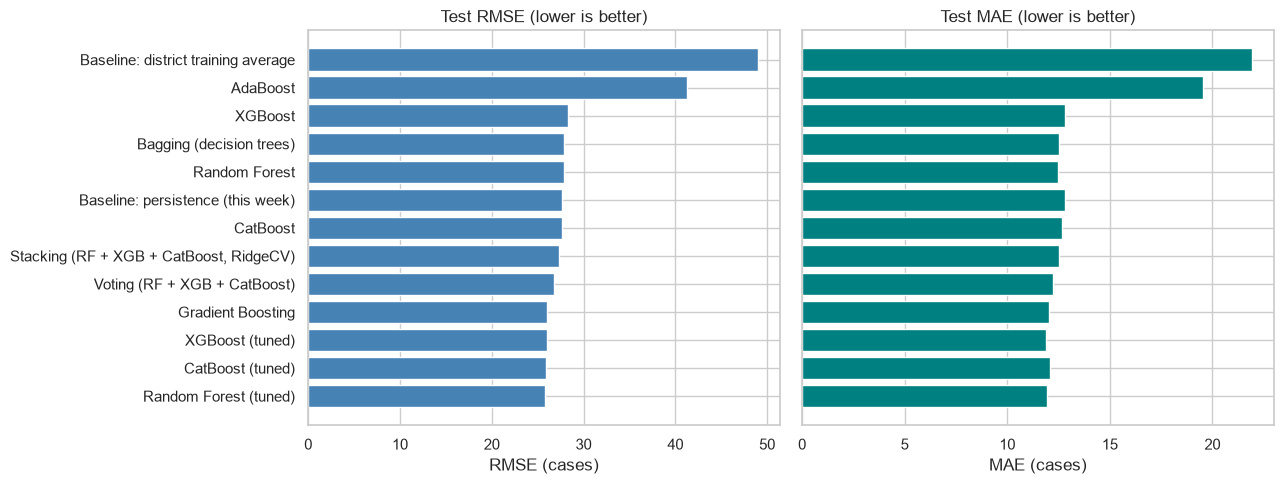

In [3]:
# AI-GENERATED (Claude via Antigravity)
plot_df = res_final.sort_values("test_RMSE", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(plot_df["model"], plot_df["test_RMSE"], color="steelblue")
axes[0].set_title("Test RMSE (lower is better)"); axes[0].set_xlabel("RMSE (cases)")
axes[1].barh(plot_df["model"], plot_df["test_MAE"], color="teal")
axes[1].set_title("Test MAE (lower is better)"); axes[1].set_xlabel("MAE (cases)")
plt.tight_layout(); plt.savefig(FIG / "07_model_rmse_mae.png", dpi=120); plt.show()

## 3. Actual vs predicted over the test period (4 diverse districts)
We pick 4 districts from training-set characteristics:
- **Large population:** highest average population
- **Small population:** lowest average population
- **Big outbreaks:** highest single-week peak in training (excluding the largest if already picked)
- **Few cases:** lowest median weekly cases in training (excluding the smallest if already picked)

Selected districts: [('Colombo', 'Large population'), ('Mullaitivu', 'Small population'), ('Gampaha', 'Big outbreaks'), ('Kilinochchi', 'Few cases')]


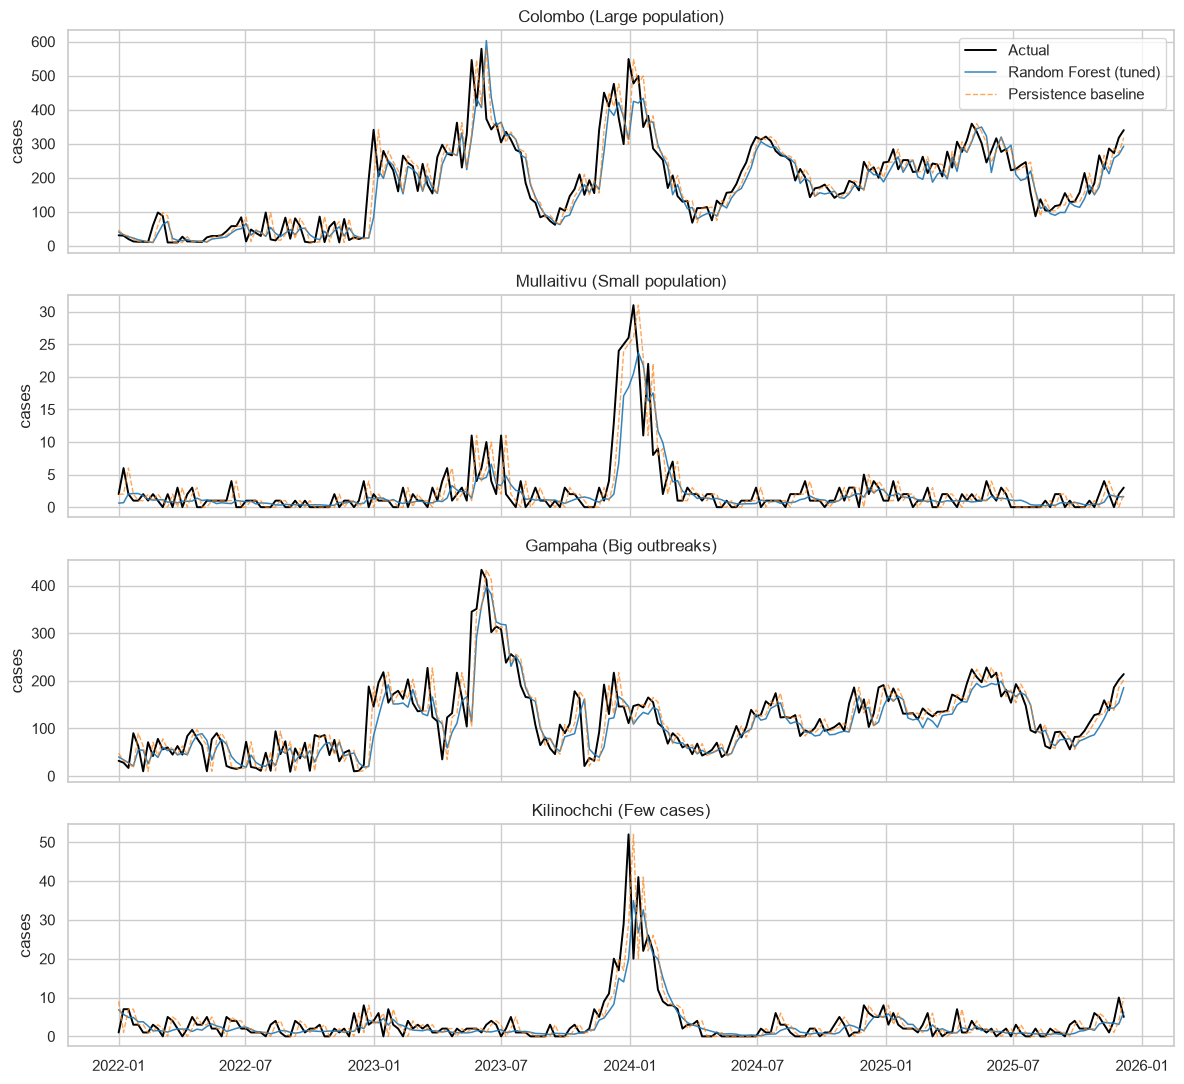

In [4]:
# AI-GENERATED (Claude via Antigravity)
best_name = "Random Forest (tuned)"
test_eval = test[[DATE, DISTRICT, TARGET_RAW]].copy()
test_eval["pred_best"] = preds[best_name]
test_eval["pred_base"] = preds["Baseline: persistence (this week)"]

stats = train.groupby(DISTRICT).agg(pop=("population", "mean"), peak=(TARGET_RAW, "max"), med=(TARGET_RAW, "median"))
d_large = stats["pop"].idxmax()
d_small = stats["pop"].idxmin()
d_outbreak = stats.drop([d_large, d_small])["peak"].idxmax()
d_few = stats.drop([d_large, d_small, d_outbreak])["med"].idxmin()
four = [(d_large, "Large population"), (d_small, "Small population"),
        (d_outbreak, "Big outbreaks"), (d_few, "Few cases")]
print("Selected districts:", four)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, (dist, label) in zip(axes, four):
    sub = test_eval[test_eval[DISTRICT] == dist].sort_values(DATE)
    ax.plot(sub[DATE], sub[TARGET_RAW], label="Actual", color="black", lw=1.4)
    ax.plot(sub[DATE], sub["pred_best"], label=best_name, color="tab:blue", lw=1.1, alpha=0.9)
    ax.plot(sub[DATE], sub["pred_base"], label="Persistence baseline", color="tab:orange", ls="--", lw=1.0, alpha=0.7)
    ax.set_title(f"{dist} ({label})"); ax.set_ylabel("cases")
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "07_actual_vs_predicted_4districts.png", dpi=120); plt.show()

## 4. Residual analysis: residuals over time & top 10 worst districts by RMSE

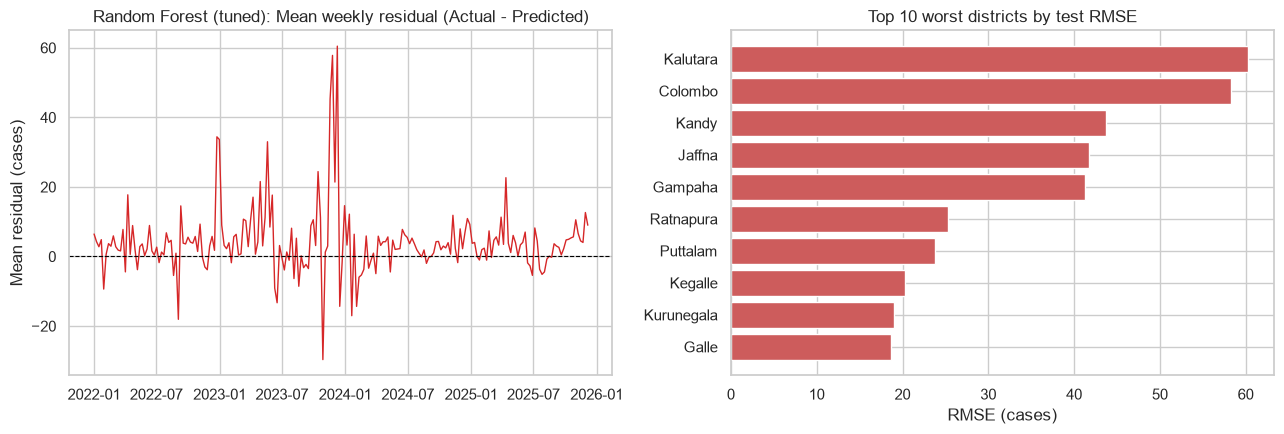

,test_RMSE
district,
Kalutara,60.28
Colombo,58.26
Kandy,43.75
Jaffna,41.79
Gampaha,41.23
Ratnapura,25.25
Puttalam,23.84
Kegalle,20.24
Kurunegala,19.00


In [5]:
# AI-GENERATED (Claude via Antigravity)
test_eval["residual"] = test_eval[TARGET_RAW] - test_eval["pred_best"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
weekly_res = test_eval.groupby(DATE)["residual"].mean()
axes[0].plot(weekly_res.index, weekly_res.values, color="tab:red", lw=1)
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_title(f"{best_name}: Mean weekly residual (Actual - Predicted)")
axes[0].set_ylabel("Mean residual (cases)")

dist_rmse = test_eval.groupby(DISTRICT).apply(lambda g: np.sqrt(np.mean(g["residual"] ** 2))).sort_values(ascending=False)
top10 = dist_rmse.head(10).sort_values()
axes[1].barh(top10.index, top10.values, color="indianred")
axes[1].set_title("Top 10 worst districts by test RMSE"); axes[1].set_xlabel("RMSE (cases)")
plt.tight_layout(); plt.savefig(FIG / "07_residuals.png", dpi=120); plt.show()
display(dist_rmse.head(10).round(2).to_frame("test_RMSE"))

## 5. Error during outbreak weeks vs normal weeks
An **outbreak week** is defined as `target_next_cases` above that district's **90th percentile in the training data**.

In [6]:
# AI-GENERATED (Claude via Antigravity)
thresh = train.groupby(DISTRICT)[TARGET_RAW].quantile(0.90)
test_eval["thresh_90"] = test_eval[DISTRICT].map(thresh)
test_eval["is_outbreak"] = test_eval[TARGET_RAW] > test_eval["thresh_90"]
print(f"Test outbreak weeks: {test_eval['is_outbreak'].sum():,} / {len(test_eval):,} ({test_eval['is_outbreak'].mean()*100:.1f}%)")

regime_rows = []
for mname in ["Random Forest (tuned)", "CatBoost (tuned)", "XGBoost (tuned)", "Baseline: persistence (this week)"]:
    for reg_label, mask in [("Outbreak (>90th pct)", test_eval["is_outbreak"]), ("Normal (<=90th pct)", ~test_eval["is_outbreak"])]:
        sc = regression_scores(test_eval.loc[mask, TARGET_RAW], preds[mname][mask])
        regime_rows.append({"model": mname, "regime": reg_label, "MAE": sc["MAE"], "RMSE": sc["RMSE"]})
display(pd.DataFrame(regime_rows).pivot(index="model", columns="regime", values=["MAE", "RMSE"]).round(2))

Test outbreak weeks: 695 / 5,150 (13.5%)


MAE                       \
regime                            Normal (<=90th pct) Outbreak (>90th pct)   
model                                                                        
Baseline: persistence (this week)               10.53                27.36   
CatBoost (tuned)                                 9.54                28.48   
Random Forest (tuned)                            9.44                28.08   
XGBoost (tuned)                                  9.41                27.99   

                                                 RMSE                       
regime                            Normal (<=90th pct) Outbreak (>90th pct)  
model                                                                       
Baseline: persistence (this week)               21.76                51.39  
CatBoost (tuned)                                18.46                52.86  
Random Forest (tuned)                           18.42                52.46  
XGBoost (tuned)                                 18.41                53.14

## 6. Classification view: catching outbreak weeks
We label a week as an **outbreak** (`1`) if `actual > thresh_90`, and a model's prediction as an **outbreak alarm** (`1`) if `predicted > thresh_90`.

**Cost of errors in public health:**
- **False Negative (missed outbreak):** Health authorities are not warned before a surge. Vector control (fogging, breeding-site cleanup) and hospital ward/platelet preparation are delayed, leading to preventable severe dengue cases and deaths.
- **False Positive (false alarm):** Extra inspection/fogging crews are deployed unnecessarily. That wastes budget and can cause alert fatigue, which is far less costly than missing a real outbreak.

,model,Accuracy,Precision,Recall,F1
3,Baseline: persistence (this week),0.903,0.642,0.643,0.643
1,CatBoost (tuned),0.913,0.730,0.565,0.637
2,XGBoost (tuned),0.913,0.743,0.545,0.629
0,Random Forest (tuned),0.912,0.734,0.541,0.623


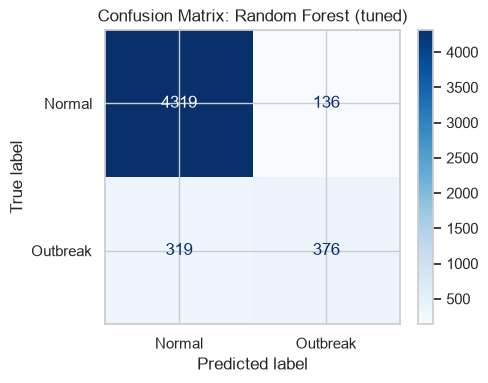

In [7]:
# AI-GENERATED (Claude via Antigravity)
y_true_cls = test_eval["is_outbreak"].astype(int).to_numpy()
cls_rows = []
for mname in ["Random Forest (tuned)", "CatBoost (tuned)", "XGBoost (tuned)", "Baseline: persistence (this week)"]:
    y_pred_cls = (preds[mname] > test_eval["thresh_90"].to_numpy()).astype(int)
    cls_rows.append({
        "model": mname,
        "Accuracy": accuracy_score(y_true_cls, y_pred_cls),
        "Precision": precision_score(y_true_cls, y_pred_cls, zero_division=0),
        "Recall": recall_score(y_true_cls, y_pred_cls, zero_division=0),
        "F1": f1_score(y_true_cls, y_pred_cls, zero_division=0),
    })
display(pd.DataFrame(cls_rows).sort_values("F1", ascending=False).round(3))

best_cls = (preds[best_name] > test_eval["thresh_90"].to_numpy()).astype(int)
cm = confusion_matrix(y_true_cls, best_cls)
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Outbreak"])
fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"Confusion Matrix: {best_name}")
plt.tight_layout(); plt.savefig(FIG / "07_confusion_matrix.png", dpi=120); plt.show()

## 7. 95% Bootstrap confidence intervals for RMSE (resampling test weeks)
We resample **entire test weeks** (all 25 districts in a week together) 1,000 times with replacement so spatial correlations across Sri Lanka are preserved.

In [8]:
# AI-GENERATED (Claude via Antigravity)
rng = np.random.default_rng(42)
weeks = test_eval[DATE].unique()
week_idx = [np.where(test_eval[DATE].to_numpy() == w)[0] for w in weeks]
top3 = ["Random Forest (tuned)", "CatBoost (tuned)", "XGBoost (tuned)", "Baseline: persistence (this week)"]

boot = {m: [] for m in top3}
y_arr = test_eval[TARGET_RAW].to_numpy()
for _ in range(1000):
    chosen = rng.integers(0, len(weeks), size=len(weeks))
    idx = np.concatenate([week_idx[c] for c in chosen])
    yt = y_arr[idx]
    for m in top3:
        boot[m].append(np.sqrt(np.mean((yt - preds[m][idx]) ** 2)))

ci_rows = []
for m in top3:
    arr = np.array(boot[m])
    ci_rows.append({"model": m, "RMSE_point": np.sqrt(np.mean((y_arr - preds[m]) ** 2)),
                    "CI_low_2.5%": np.percentile(arr, 2.5), "CI_high_97.5%": np.percentile(arr, 97.5)})
display(pd.DataFrame(ci_rows).round(3))

# Paired bootstrap difference: Persistence minus Random Forest (tuned)
diff_base = np.array(boot["Baseline: persistence (this week)"]) - np.array(boot["Random Forest (tuned)"])
print(f"RMSE improvement over persistence: mean = {diff_base.mean():.2f}, 95% CI = [{np.percentile(diff_base, 2.5):.2f}, {np.percentile(diff_base, 97.5):.2f}]")
diff_cb = np.array(boot["CatBoost (tuned)"]) - np.array(boot["Random Forest (tuned)"])
print(f"CatBoost minus RF (tuned):         mean = {diff_cb.mean():.2f}, 95% CI = [{np.percentile(diff_cb, 2.5):.2f}, {np.percentile(diff_cb, 97.5):.2f}]")

,model,RMSE_point,CI_low_2.5%,CI_high_97.5%
0,Random Forest (tuned),25.787,20.913,30.908
1,CatBoost (tuned),25.921,21.113,30.947
2,XGBoost (tuned),25.965,20.847,31.532
3,Baseline: persistence (this week),27.677,22.977,32.732


RMSE improvement over persistence: mean = 1.90, 95% CI = [-0.13, 4.12]
CatBoost minus RF (tuned):         mean = 0.14, 95% CI = [-0.58, 0.77]
